In [3]:
import glob, os, shutil
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingRegressor

In [4]:
seed = 0
first_year = 2012
train_end = 2018
target = "ND"
os.makedirs("data", exist_ok=True)
os.makedirs("results", exist_ok=True)


In [5]:
from google.colab import files
up = files.upload()
for name in up:
    shutil.move(name, "data/" + name)
print(sorted(os.listdir("data")))

Saving demanddata_2012.csv to demanddata_2012.csv
Saving demanddata_2013.csv to demanddata_2013.csv
Saving demanddata_2014.csv to demanddata_2014.csv
Saving demanddata_2015.csv to demanddata_2015.csv
Saving demanddata_2016.csv to demanddata_2016.csv
Saving demanddata_2017.csv to demanddata_2017.csv
Saving demanddata_2018.csv to demanddata_2018.csv
Saving demanddata_2019.csv to demanddata_2019.csv
Saving demanddata_2020.csv to demanddata_2020.csv
Saving demanddata_2021.csv to demanddata_2021.csv
Saving demanddata_2022.csv to demanddata_2022.csv
Saving demanddata_2023.csv to demanddata_2023.csv
Saving demanddata_2024.csv to demanddata_2024.csv
Saving demanddata_2025.csv to demanddata_2025.csv
Saving demanddataupdate_2026.csv to demanddataupdate_2026.csv
['demanddata_2012.csv', 'demanddata_2013.csv', 'demanddata_2014.csv', 'demanddata_2015.csv', 'demanddata_2016.csv', 'demanddata_2017.csv', 'demanddata_2018.csv', 'demanddata_2019.csv', 'demanddata_2020.csv', 'demanddata_2021.csv', 'demand

In [7]:
def load(folder):
    files_ = sorted(glob.glob(os.path.join(folder, "*.csv")))
    if not files_:
        raise SystemExit("No CSV files found in data/")
    frames = []
    for f in files_:
        d = pd.read_csv(f)
        d.columns = [c.strip().upper() for c in d.columns]
        need = {"SETTLEMENT_DATE", "SETTLEMENT_PERIOD", target}
        if not need.issubset(d.columns):
            print(f"Skipping {os.path.basename(f)}: missing columns {need - set(d.columns)}")
            continue
        frames.append(d[["SETTLEMENT_DATE", "SETTLEMENT_PERIOD", target]])
    df = pd.concat(frames, ignore_index=True)
    df["date"] = pd.to_datetime(df["SETTLEMENT_DATE"], format="mixed", dayfirst=True)
    df = df.rename(columns={"SETTLEMENT_PERIOD": "period", target: "y"})
    df = df[["date", "period", "y"]].drop_duplicates(["date", "period"]).sort_values(["date", "period"])
    return df[(df["y"] > 0) & (df["date"].dt.year >= first_year)].reset_index(drop=True)

def add_features(df):
    out = df.copy()
    for k in range(1, 8):
        lag = df[["date", "period", "y"]].copy()
        lag["date"] = lag["date"] + pd.Timedelta(days=k)
        out = out.merge(lag.rename(columns={"y": f"lag{k}"}), on=["date", "period"], how="left")
    lag_cols = [f"lag{k}" for k in range(1, 8)]
    out["mean7"] = out[lag_cols].mean(axis=1)
    out["dow"] = out["date"].dt.dayofweek
    out["doy_sin"] = np.sin(2 * np.pi * out["date"].dt.dayofyear / 365.25)
    out["doy_cos"] = np.cos(2 * np.pi * out["date"].dt.dayofyear / 365.25)
    out["year"] = out["date"].dt.year
    return out.dropna(subset=lag_cols).reset_index(drop=True)

features = ["period", "dow", "doy_sin", "doy_cos", "lag1", "lag2", "lag7", "mean7"]

def wape(y, p):
    return 100 * np.abs(y - p).sum() / np.abs(y).sum()

def fit(train):
    m = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, max_leaf_nodes=15,
                                      l2_regularization=1.0, random_state=seed)
    return m.fit(train[features], train["y"])

258192 half-hours, 2012 - 2026
 year  mean_demand_MW  same_time_yesterday  same_time_last_week  mean_of_last_7_days  gbm_frozen  gbm_retrained_yearly
 2019        29360.29                 6.88                 6.64                 7.24        4.10                  4.10
 2020        27160.16                 6.81                 7.16                 7.28        5.09                  4.93
 2021        28350.21                 6.22                 7.04                 6.63        4.29                  4.15
 2022        26624.08                 6.96                 7.60                 7.64        5.01                  4.49
 2023        26054.32                 7.04                 7.85                 7.42        5.54                  4.76
 2024        26290.62                 7.24                 7.65                 7.65        5.28                  4.71
 2025        26161.18                 7.06                 8.33                 7.51        5.69                  4.96
 2026        2519

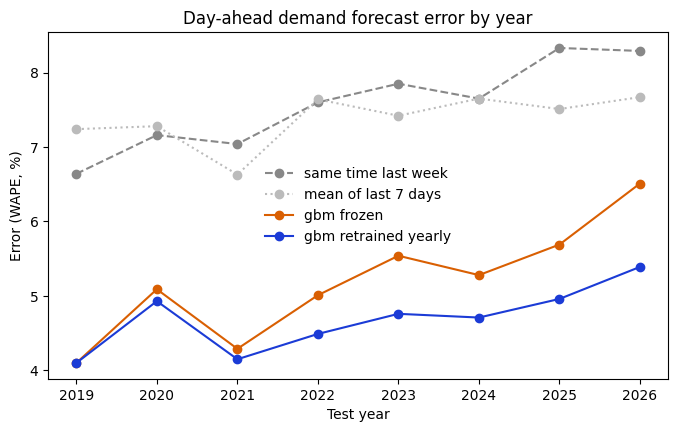

In [8]:
df = add_features(load("data"))
years = sorted(df["year"].unique())
test_years = [y for y in years if y > train_end]
print(len(df), "half-hours,", years[0], "-", years[-1])

frozen = fit(df[df["year"] <= train_end])
rows = []
for y in test_years:
    te = df[df["year"] == y]
    retrained = fit(df[df["year"] < y])
    rows.append({
        "year": y,
        "mean_demand_MW": te["y"].mean(),
        "same_time_yesterday": wape(te["y"], te["lag1"]),
        "same_time_last_week": wape(te["y"], te["lag7"]),
        "mean_of_last_7_days": wape(te["y"], te["mean7"]),
        "gbm_frozen": wape(te["y"], frozen.predict(te[features])),
        "gbm_retrained_yearly": wape(te["y"], retrained.predict(te[features])),
    })
res = pd.DataFrame(rows).round(2)
res.to_csv("results/wape_by_year.csv", index=False)
print(res.to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 4.5))
for c, col, ls in [("same_time_last_week", "#888888", "--"), ("mean_of_last_7_days", "#bbbbbb", ":"),
                   ("gbm_frozen", "#d95f02", "-"), ("gbm_retrained_yearly", "#1b3bd6", "-")]:
    ax.plot(res["year"], res[c], color=col, linestyle=ls, marker="o", label=c.replace("_", " "))
ax.set_ylabel("Error (WAPE, %)"); ax.set_xlabel("Test year")
ax.set_title("Day-ahead demand forecast error by year"); ax.legend(frameon=False)
plt.show()